### This Demo notebook provides a walkthrough over each of the modules described in the report.

* They can each be run as standalone modules on colab and its recommended to delete/restart your runtime when running a new one as certain librairies might clash.

## The integrated system at the end combines these modules in a practical way to showcase how an intelligent neuromorphic vision sensor would be used in live application.  

### **Photosensor Circuit**

Simluated using Pyspice.
* Only runs on for a small fragment of the input video due to computational complexity.

** Note: Running this on a colab notebook is difficult and will probably encounter errors due to the need for an accompanying LTspice exucatable using the app. Further instructions in the code are given to run it locally.

In [1]:
!pip install PyLTSpice

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.6/64.6 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 241.5/241.5 kB 10.6 MB/s eta 0:00:00


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import csv
from PyLTSpice import SimCommander, RawRead # Requires python >= 3.9
import os
from pathlib import Path
import shutil

##### This script will not run unless it is ran locally on a machine with LTSpice installed #####
##### If an error is thrown that LTSpice the app cannot be found see line ~150 for the fix #####

# ON = 1 will execute video creation, SPEED = 0 will execute dyanmic thresholds
ON = 0
SPEED = 0
# I placed these to speedup my test runs - Jacob

# Change to absolute path of desired video
video_path = "/content/marco.MOV"

# Defines box side length in pixels to simulate through LTSpice (Choose an even value)
SPICE_GRID_SIZE = 2        # DO NOT CHANGE UNLESS YOU KNOW WHAT YOU'RE DOING
# Total pixels ran through LTSpice per frame will be (SPICE_GRID_SIZE^2)

# Store Temporary Files From LTSpice simulations
LTSPICE_CACHE = Path("LTSpice_cache")
LTSPICE_CACHE.mkdir(exist_ok=True)

# Function to emulate dvs analysis
# Passes in a fixed-frame video, displays intensity change at pixel and time
def dvs_emulate(video, timestamps, C_on, C_off):

    # Video parameter definition: number of frames, vertical and horizontal pixels
    T, H, W = video.shape
    eps = 1e-3  # to avoid log(0), shifts all intensities slightly
    clip_min = 1e-2 # To reduce the log(close to 0) max/min delta increase
    logIntensity = np.log(np.clip(video, clip_min, 1.0) + eps) # Takes log of offset and clipped video intensities

    last_event_time = np.full((H, W), -np.inf) # Take time of event

    prev_logIntensity = logIntensity[0].copy() # Set the previous intensity
    events = [] # Initialize events array
    ltspice_events = [] # Initialize LTSpice events array

    # Validation tracking
    correct = 0
    incorrect = 0

    for i in range(1, T):

        half_grid = SPICE_GRID_SIZE // 2
        # DO NOT CHANGE UNTIL YOU KNOW WHAT YOU ARE DOING THIS WILL MASSIVELY INFLUENCE RUNTIME #
        ystart, yend = H // 2 - half_grid, H // 2 + half_grid       # Written as such to capture near the center of the scene
        xstart, xend = W // 2 - half_grid, W // 2 + half_grid       # These can be manually changed to pixels you want to
        frame_start, frame_end = 60, 65                             # specifically target - Jacob
        #########################################################################################

        if frame_start <= i < frame_end:
            # Because we start midway through video we can't initialize from zero so we do it as such
            if i == frame_start:
                ref_initial = np.zeros((yend-ystart, xend-xstart))
                ref_initial[:, :] = np.log(np.clip(video[i-1, ystart:yend, xstart:xend], clip_min, 1.0) + eps)
                print("Status Update: LTSpice Simulations Starting (This may be time consuming)")

            # Compute the emulated DVS deltas within the ROI for the frame
            delta_region = logIntensity[i, ystart:yend, xstart:xend] - logIntensity[i-1, ystart:yend, xstart:xend]


            for y in range(ystart, yend):
                for x in range(xstart, xend):
                    apparenty = y-ystart
                    apparentx = x-xstart

                    current_raw = np.clip(video[i, y, x], clip_min, 1.0)
                    prev_intensity = ref_initial[apparenty, apparentx]
                    spice_event, vref_at_sim_end = LTSpiceSim(current_raw, prev_intensity, C_on, abs(C_off))

                    # Determine what the emulator logic predicts for this pixel
                    if delta_region[apparenty, apparentx] >= C_on:
                        emulated_event = +1
                    elif delta_region[apparenty, apparentx] <= C_off:
                        emulated_event = -1
                    else:
                        emulated_event = 0

                    # Compare LTSpice event with emulated event
                    if spice_event == emulated_event:
                        correct += 1
                    else:
                        incorrect += 1

                    # Update memory for NEXT frame, Note: This replaces a reset switch in the circuit model
                    ref_initial[apparenty, apparentx] = vref_at_sim_end

                    if spice_event != 0:
                        ltspice_events.append([x, y, timestamps[i], spice_event])
                        print(f"Frame: {i}, Location: x={x} y={y}, Event: {spice_event}")


        if i == frame_end-1:
            print("Status Update: All LTSpice Simulations Complete")
            print("\nValidation Statistics")
            print(f"Total Pixels Simulated: {(yend-ystart)*(xend-xstart)*(frame_end-frame_start)}")
            print(f"Correct Predictions: {correct}")
            print(f"Incorrect Predictions: {incorrect}")
            print(f"Validation Accuracy: {100*correct/(correct+incorrect)}%")

        delta = logIntensity[i] - prev_logIntensity # Compute log intensity difference

        # Positive (brighter)
        on_mask = delta >= C_on
        # Negative (darker)
        off_mask = delta <= C_off

        # Extract coordinates for both types
        on_y, on_x = np.nonzero(on_mask)
        off_y, off_x = np.nonzero(off_mask)

        # Append ON events
        for y, x in zip(on_y, on_x):
            events.append([x, y, timestamps[i], +1])
            last_event_time[y, x] = timestamps[i]

        # Append OFF events
        for y, x in zip(off_y, off_x):
            events.append([x, y, timestamps[i], -1])
            last_event_time[y, x] = timestamps[i]

        # Reset reference intensity where events occurred
        prev_logIntensity = logIntensity[i]

    return np.array(events), np.array(ltspice_events)

# Handles all pipelining between python and LTSpice
def LTSpiceSim(current_raw, prev_intensity, C_on, C_off):

    # Gather netlist path and top level working directory
    netlist_path = Path("DVS_Pixel.net").resolve()
    original_cwd = os.getcwd()

    try:
        os.chdir(LTSPICE_CACHE) # Enter cache folder so top level directory doesn't get polluted

        # Copy netlist to cache directory
        cache_netlist = Path("DVS_Pixel.net")
        if not cache_netlist.exists() or cache_netlist.stat().st_mtime < netlist_path.stat().st_mtime:
            shutil.copy(netlist_path, cache_netlist)

        ############ FOR NO LTSPICE APP FOUND ################
        # If LTSpice is not found automatically, specify the path in SimCommander: SimCommander("DVS_Pixel.net")
        # CHANGE TO SimCommander("DVS_Pixel.net", simulator="/absolute/application/file/path")
        # For more details see https://pypi.org/project/PyLTSpice/ and https://github.com/nunobrum/spicelib/blob/main/spicelib/simulators/ltspice_simulator.py

        # Now run sim and output files within cache folder
        sim = SimCommander("DVS_Pixel.net")
        sim.set_parameters(
            VLight=current_raw,
            C_on=C_on,
            C_off=C_off,
            ref_ic=prev_intensity)

        sim.run()
        sim.wait_completion()

        # Look for .raw files in cache
        raw_files = sorted(Path(".").glob("*.raw"), key=os.path.getmtime)

        # Use the most recent .raw file (Was expecting file explosion but that didn't maintain this structure for security)
        latest_raw = raw_files[-1]
        raw = RawRead(str(latest_raw))

        # Gather relevant simulation data (Sim is 30us with 100ns steps)
        von = max(raw.get_trace("V(on)").data[:]) # Max of full sim data
        voff = min(raw.get_trace("V(off)").data[:]) # Min of full sim data
        vref_at_sim_end = raw.get_trace("V(ref)").data[-1] # Gather value at last data point

        if von > 0.5:
            event = +1
        elif voff < -0.5:
            event = -1
        else:
            event = 0

        return event, vref_at_sim_end

    finally:
        os.chdir(original_cwd)

# Capture video data
cap = cv2.VideoCapture(video_path)

# Error message if video fails to open
if not cap.isOpened():
    raise ValueError("Cannot open video")

# Initialize frame array
frames = []

# Iterate through video frames and check successful capture
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Convert to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    # Normalize to 0-1
    gray = gray.astype(np.float32) / 255.0

    # Downsample
    scale = 1
    gray_downsampled = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    frames.append(gray_downsampled)
    # Show video

# Release captured video frames
cap.release()
video = np.stack(frames)  # create 'video' out of list of frames with shape = (T, H, W)

print("Video shape:", video.shape)

if SPEED == 0:
    # Compute max and min deltas before function execution to dynamically define thresholds and print
    logIntensity = np.log(np.clip(video, 1e-2, 1.0) + 1e-3)
    delta = logIntensity[1:] - logIntensity[:-1]
    maxthresh = delta.max() - (0.9*delta.max())
    minthresh = delta.min() + (0.9*-delta.min())
else:
    maxthresh = .4003024
    minthresh = -.3729496

print("maxthresh: ", maxthresh)
print("minthresh: ", minthresh)

# Turns frame array into a series of times from frame count 'timestamps'
timestamps = np.arange(video.shape[0]) / 30

# Create events array using the function with + & - thresholds
events, ltspice_events = dvs_emulate(video, timestamps, maxthresh, minthresh)

# Cleanup LTSpice cache folder
if LTSPICE_CACHE.exists():
    shutil.rmtree(LTSPICE_CACHE)

print("Total events:", len(events))
print(f"{len(ltspice_events)} events detected by the LTSpice circuit")


Video shape: (205, 1280, 720)
maxthresh:  0.36099935
minthresh:  -0.42781258


ERROR:spicelib.LTSpiceSimulator:================== ALERT! ====================
ERROR:spicelib.LTSpiceSimulator:Unable to find a LTspice executable.
ERROR:spicelib.LTSpiceSimulator:A specific location of the LTSPICE can be set
ERROR:spicelib.LTSpiceSimulator:using the create_from(<location>) class method
ERROR:spicelib.LTSpiceSimulator:==============================================
ERROR:spicelib.RunTask:RunTask #1:Simulation Failed. SpiceSimulatorError: Simulator executable not found.
ERROR:spicelib.RunTask:RunTask #1:Simulation Aborted. Time elapsed: 00.0004 secs


Status Update: LTSpice Simulations Starting (This may be time consuming)


IndexError: list index out of range

### **Event Encoder Emulator**

Custom implementation of a RGB to Event emulator that converts RGB frames into event data stream in the form of x,y,t,p.
* Stacks the event frames to generate an event-video.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import csv

# Function to emulate dvs analysis
# Passes in a fixed-frame video, displays intensity change at pixel and time
def dvs_emulate(video, timestamps, C_on, C_off):

    # Video parameter definition: number of frames, vertical and horizontal pixels
    T, H, W = video.shape
    eps = 1e-3  # to avoid log(0), shifts all intensities slightly
    clip_min = 1e-2 # To reduce the log(close to 0) max/min delta increase
    logIntensity = np.log(np.clip(video, clip_min, 1.0) + eps) # Takes log of offset and clipped video intensities

    last_event_time = np.full((H, W), -np.inf) # Take time of event

    prev_logIntensity = logIntensity[0].copy() # Set the previous intensity
    events = [] # Initialize events array

    for i in range(1, T):

        delta = logIntensity[i] - prev_logIntensity # Compute log intensity difference

        # Positive (brighter)
        on_mask = delta >= C_on
        # Negative (darker)
        off_mask = delta <= C_off

        # Extract coordinates for both types
        on_y, on_x = np.nonzero(on_mask)
        off_y, off_x = np.nonzero(off_mask)

        # Append ON events
        for y, x in zip(on_y, on_x):
            events.append([x, y, timestamps[i], +1])
            last_event_time[y, x] = timestamps[i]

        # Append OFF events
        for y, x in zip(off_y, off_x):
            events.append([x, y, timestamps[i], -1])
            last_event_time[y, x] = timestamps[i]

        # Reset reference intensity where events occurred
        prev_logIntensity = logIntensity[i]

    return np.array(events)

# Change to absolute path of desired video
video_path = "/content/marco.MOV"

# Capture video data
cap = cv2.VideoCapture(video_path)

# Error message if video fails to open
if not cap.isOpened():
    raise ValueError("Cannot open video")

# Initialize frame array
frames = []

# Iterate through video frames and check successful capture
while True:
    ret, frame = cap.read()
    if not ret:
        break

    # Convert to grayscale
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    # Normalize to 0-1
    gray = gray.astype(np.float32) / 255.0

    # Downsample
    scale = 1
    gray_downsampled = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

    frames.append(gray_downsampled)
    # Show video

# Release captured video frames
cap.release()
video = np.stack(frames)  # create 'video' out of list of frames with shape = (T, H, W)

print("Video shape:", video.shape)

# Compute max and min deltas before function execution to dynamically define thresholds and print
logIntensity = np.log(np.clip(video, 1e-2, 1.0) + 1e-3)
delta = logIntensity[1:] - logIntensity[:-1]
maxthresh = delta.max() - (0.9*delta.max())
minthresh = delta.min() + (0.9*-delta.min())

print("maxthresh: ", maxthresh)
print("minthresh: ", minthresh)

# Turns frame array into a series of times from frame count 'timestamps'
timestamps = np.arange(video.shape[0]) / 30

# Create events array using the function with + & - thresholds
events = dvs_emulate(video, timestamps, maxthresh, minthresh)

print("Total events:", len(events))


# Create Video
H, W = video.shape[1], video.shape[2]
output_path = "dvs_events_output.mp4"
fps = 30
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(output_path, fourcc, fps, (W, H), isColor=False)

# Convert events list to numpy array
events = np.array(events)

# Frames are defined by timestamps[i] = i/30
frame_events = {i: [] for i in range(len(video))}
for x, y, t, p in events:
    frame_index = int(t * fps)  # convert time to frame index
    if frame_index < len(video):
        frame_events[frame_index].append((int(x), int(y), int(p)))

# Create video visualization
for i in range(len(video)):
    # Start with gray background
    event_frame = np.full((H, W), 128, dtype=np.uint8)

    for (x, y, polarity) in frame_events[i]:
        if polarity == +1:      # ON = bright
            event_frame[y, x] = 255
        else:                   # OFF = dark
            event_frame[y, x] = 0

    out.write(event_frame)

out.release()
print("Event video saved as:", output_path)

csv_path = "dvs_events_output.csv"

# Write header + event rows
with open(csv_path, mode="w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["x", "y", "timestamp", "polarity"])
    for x, y, t, p in events:
        writer.writerow([int(x), int(y), float(t), int(p)])

print("CSV saved as:", csv_path)

Video shape: (205, 1280, 720)
maxthresh:  0.36099935
minthresh:  -0.42781258
Total events: 2981485
Event video saved as: dvs_events_output.mp4
CSV saved as: dvs_events_output.csv


### **DVSGesture Model Eval**

Use the trained DVSGesture SNN to predict gestures for sample event-based test data.
* Visualizations show how the model 'sees' the transformed data

In [3]:
import warnings

# Ignore all UserWarnings, which includes matplotlib clipping warnings.
warnings.filterwarnings("ignore")

# You can also use this to ignore all warnings, if desired:
# warnings.filterwarnings("ignore")

In [10]:
!pip -q install tonic snntorch
!pip install numpy==2.0.0 --quiet
# !git clone https://github.com/SensorsINI/v2e
# !pip -q install -e v2e

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.0/19.0 MB 53.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tonic 1.6.0 requires numpy<2.0.0, but you have numpy 2.0.0 which is incompatible.


In [11]:
import torch
import torch.nn as nn
import snntorch as snn
from snntorch import functional as SF

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

grad = snn.surrogate.fast_sigmoid(slope=25)
beta = 0.5

net = nn.Sequential(
    nn.Conv2d(2, 12, 5),
    nn.MaxPool2d(2),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True),
    nn.Conv2d(12, 32, 5),
    nn.MaxPool2d(2),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True),
    nn.Flatten(),
    nn.Linear(800, 11),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True, output=True)
).to(device)

# Load your saved state_dict
WEIGHTS = "/content/model.pth"  # <-- change to your file
net.load_state_dict(torch.load(WEIGHTS, map_location=device))
net.eval()
print("Loaded weights.")


Loaded weights.


In [26]:
import tonic
import tonic.transforms as TT
import numpy as np
import torch
import torch.nn.functional as F
from snntorch import utils
from IPython.display import HTML, display
import logging

# Suppress matplotlib.image clipping warnings by setting its logger level to ERROR
logging.getLogger('matplotlib.image').setLevel(logging.ERROR)

# ----- your label names -----
gesture_labels = [
    "hand clapping",
    "right hand wave",
    "left hand wave",
    "right arm clockwise",
    "right arm counter clockwise",
    "left arm clockwise",
    "left arm counter clockwise",
    "arm roll",
    "air drums", "air guitar", "other"
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device).eval()

@torch.no_grad()
def forward_pass(net, data_TBCHW):
    spk_rec = []
    utils.reset(net)
    for t in range(data_TBCHW.size(0)):
        spk_out, _ = net(data_TBCHW[t])  # [B,11]
        spk_rec.append(spk_out)
    return torch.stack(spk_rec)          # [T,B,11]

@torch.no_grad()
def predict_from_frames(frames_TCHW):
    # frames_TCHW expected [T,2,32,32] exactly like training (NO extra normalization)
    x = torch.tensor(frames_TCHW, dtype=torch.float32).unsqueeze(1).to(device)  # [T,1,2,32,32]
    spk_rec = forward_pass(net, x)
    spk_counts = spk_rec.sum(dim=0).squeeze(0)  # [11]
    probs = F.softmax(spk_counts, dim=0).cpu().numpy()
    pred = int(np.argmax(probs))
    conf = float(np.max(probs))
    return pred, conf, probs

# ----- Load raw events (no transform) -----
dataset_path = "DVSGesture_raw"  # change if needed
test_raw = tonic.datasets.DVSGesture(save_to=dataset_path, train=False, transform=None)
# ----- Full-res visualization transform (128x128) -----
viz_transform = TT.Compose([
    TT.Denoise(filter_time=10000),
    TT.ToFrame(sensor_size=tonic.datasets.DVSGesture.sensor_size, time_window=10000)  # 10ms bins
])


# ----- Model transform (what you trained on) -----
model_transform = TT.Compose([
    TT.Denoise(filter_time=10000),
    TT.Downsample(sensor_size=tonic.datasets.DVSGesture.sensor_size, target_size=(32, 32)),
    TT.ToFrame(sensor_size=(32, 32, 2), n_time_bins=32),
])



Sample 0
True: 0 hand clapping
Pred: 0 hand clapping (conf=1.00)

Full-res (128x128) visualization:


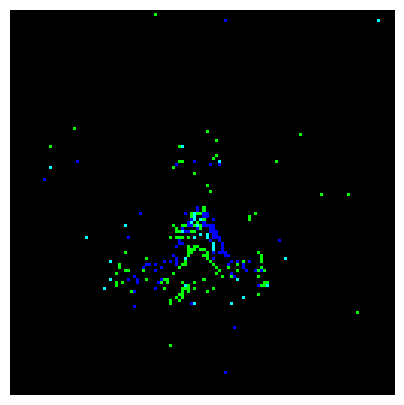


Model input (32x32) visualization (what the network actually sees):


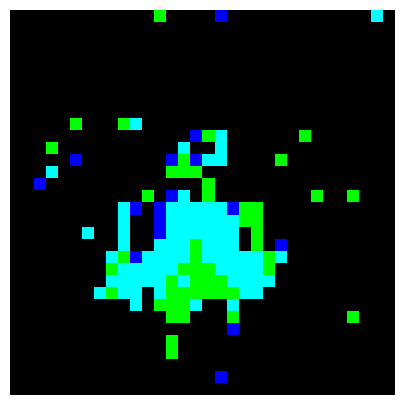

In [27]:
## CHANGE THE VALUES AS DESIRED FROM 0-10 TO TEST DIFFERENT SAMPLES

# pick a sample
idx = 0
events, y = test_raw[idx]
y = int(y)

frames_full = viz_transform(events)  # [Tviz,2,128,128]
frames_model = model_transform(events)  # [32,2,32,32]

# ----- Predict -----
pred, conf, probs = predict_from_frames(frames_model)

print(f"Sample {idx}")
print("True:", y, gesture_labels[y])
print("Pred:", pred, gesture_labels[pred], f"(conf={conf:.2f})")

# ----- Show videos -----
print("\nFull-res (128x128) visualization:")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_full).to_jshtml()))

print("\nModel input (32x32) visualization (what the network actually sees):")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_model).to_jshtml()))

Sample 1
True: 9 air guitar
Pred: 10 other (conf=1.00)

Full-res (128x128) visualization:


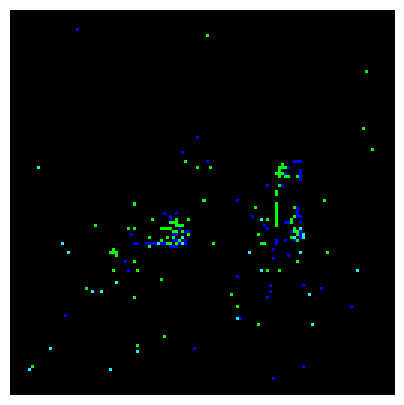


Model input (32x32) visualization (what the network actually sees):


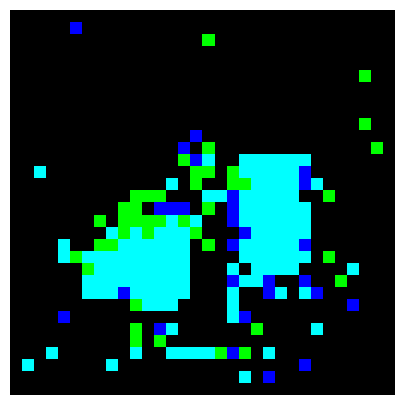

In [28]:
## CHANGE THE VALUES AS DESIRED FROM 0-10 TO TEST DIFFERENT SAMPLES

# pick a sample
idx = 1
events, y = test_raw[idx]
y = int(y)

frames_full = viz_transform(events)  # [Tviz,2,128,128]
frames_model = model_transform(events)  # [32,2,32,32]

# ----- Predict -----
pred, conf, probs = predict_from_frames(frames_model)

print(f"Sample {idx}")
print("True:", y, gesture_labels[y])
print("Pred:", pred, gesture_labels[pred], f"(conf={conf:.2f})")

# ----- Show videos -----
print("\nFull-res (128x128) visualization:")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_full).to_jshtml()))

print("\nModel input (32x32) visualization (what the network actually sees):")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_model).to_jshtml()))

Sample 2
True: 4 right arm counter clockwise
Pred: 4 right arm counter clockwise (conf=1.00)

Full-res (128x128) visualization:


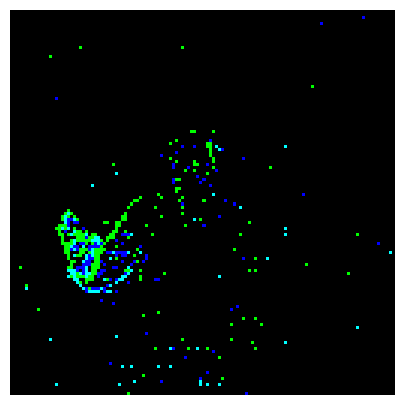


Model input (32x32) visualization (what the network actually sees):


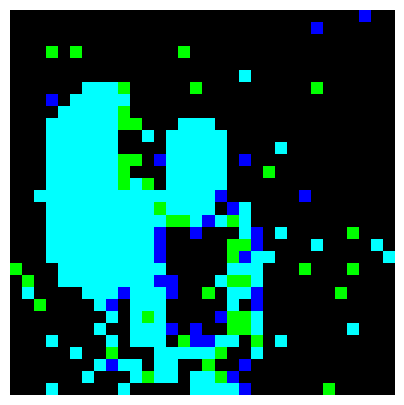

In [29]:
## CHANGE THE VALUES AS DESIRED FROM 0-10 TO TEST DIFFERENT SAMPLES

# pick a sample
idx = 2
events, y = test_raw[idx]
y = int(y)

frames_full = viz_transform(events)  # [Tviz,2,128,128]
frames_model = model_transform(events)  # [32,2,32,32]

# ----- Predict -----
pred, conf, probs = predict_from_frames(frames_model)

print(f"Sample {idx}")
print("True:", y, gesture_labels[y])
print("Pred:", pred, gesture_labels[pred], f"(conf={conf:.2f})")

# ----- Show videos -----
print("\nFull-res (128x128) visualization:")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_full).to_jshtml()))

print("\nModel input (32x32) visualization (what the network actually sees):")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_model).to_jshtml()))

Sample 3
True: 2 left hand wave
Pred: 2 left hand wave (conf=1.00)

Full-res (128x128) visualization:


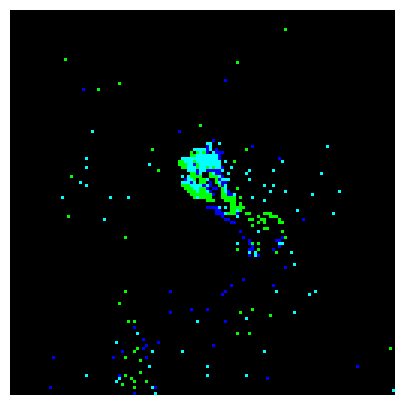


Model input (32x32) visualization (what the network actually sees):


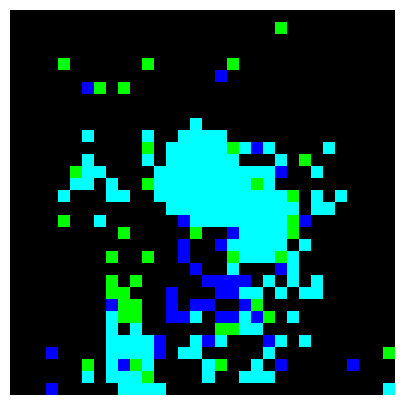

In [30]:
## CHANGE THE VALUES AS DESIRED FROM 0-10 TO TEST DIFFERENT SAMPLES

# pick a sample
idx = 3
events, y = test_raw[idx]
y = int(y)

frames_full = viz_transform(events)  # [Tviz,2,128,128]
frames_model = model_transform(events)  # [32,2,32,32]

# ----- Predict -----
pred, conf, probs = predict_from_frames(frames_model)

print(f"Sample {idx}")
print("True:", y, gesture_labels[y])
print("Pred:", pred, gesture_labels[pred], f"(conf={conf:.2f})")

# ----- Show videos -----
print("\nFull-res (128x128) visualization:")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_full).to_jshtml()))

print("\nModel input (32x32) visualization (what the network actually sees):")
# Pass frames directly, warnings for clipping will be suppressed by the logger setting
display(HTML(tonic.utils.plot_animation(frames_model).to_jshtml()))

### **Integrated System**

A full end-end pipeline that can be implemented in practice using the modules described in the report.
* Make a gesture prediction on a sample input RGB video using the trained SNN

Upload the model weights

In [2]:
from google.colab import files

print("Please upload the pre-trained SNN model file (model.pth):")
uploaded_model = files.upload()

# The file will be uploaded to the current content directory.
# No further action needed here as the model loading code expects it at /content/DVSGestureSNN.pth
print(f"Uploaded model file: {list(uploaded_model.keys())[0]}")

Please upload the pre-trained SNN model file (model.pth):


Saving DVSGestureSNN.pth to DVSGestureSNN.pth
Uploaded model file: DVSGestureSNN.pth


Upload a sample video to predict the gesture on.

We then Use our event encoding emulator to generate event data from the uploaded RGB video.

In [10]:
import numpy as np
import cv2

def dvs_emulate(video, timestamps, C_on, C_off):

    # Video parameter definition: number of frames, vertical and horizontal pixels
    T, H, W = video.shape
    eps = 1e-3  # to avoid log(0), shifts all intensities slightly
    clip_min = 1e-2 # To reduce the log(close to 0) max/min delta increase
    logIntensity = np.log(np.clip(video, clip_min, 1.0) + eps) # Takes log of offset and clipped video intensities

    last_event_time = np.full((H, W), -np.inf) # Take time of event

    prev_logIntensity = logIntensity[0].copy() # Set the previous intensity
    events = [] # Initialize events array

    for i in range(1, T):

        delta = logIntensity[i] - prev_logIntensity # Compute log intensity difference

        # Positive (brighter)
        on_mask = delta >= C_on
        # Negative (darker)
        off_mask = delta <= C_off

        # Extract coordinates for both types
        on_y, on_x = np.nonzero(on_mask)
        off_y, off_x = np.nonzero(off_mask)

        # Append ON events
        for y, x in zip(on_y, on_x):
            events.append([x, y, timestamps[i], +1])
            last_event_time[y, x] = timestamps[i]

        # Append OFF events
        for y, x in zip(off_y, off_x):
            events.append([x, y, timestamps[i], -1])
            last_event_time[y, x] = timestamps[i]

        # Reset reference intensity where events occurred
        prev_logIntensity = logIntensity[i]

    return np.array(events)


from google.colab import files

print("Please upload your video file (e.g., .mp4, .mov):")
uploaded = files.upload()

# Re-load the video from the uploaded file as `video` was not defined
video_filename = list(uploaded.keys())[0] # Assuming uploaded_video is still available
cap = cv2.VideoCapture(video_filename)

if not cap.isOpened():
    raise ValueError("Cannot open video file. Please check the file path and format.")

frames = []
original_fps = cap.get(cv2.CAP_PROP_FPS)
if original_fps == 0:
    original_fps = 30

while True:
    ret, frame = cap.read()
    if not ret:
        break
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gray = gray.astype(np.float32) / 255.0
    frames.append(gray)
cap.release()
video = np.stack(frames)

print(f"Video re-loaded: {video_filename}")
print("Video shape:", video.shape)
print(f"Original video FPS: {original_fps}")


# Compute max and min deltas before function execution to dynamically define thresholds
logIntensity_full = np.log(np.clip(video, 1e-2, 1.0) + 1e-3)
delta_full = logIntensity_full[1:] - logIntensity_full[:-1]
maxthresh = delta_full.max() - (0.9*delta_full.max())
minthresh = delta_full.min() + (0.9*-delta_full.min())

print("maxthresh: ", maxthresh)
print("minthresh: ", minthresh)

# Turns frame array into a series of times from frame count 'timestamps'
timestamps = np.arange(video.shape[0]) / original_fps

# Create events array using the function with + & - thresholds
events = dvs_emulate(video, timestamps, maxthresh, minthresh)

print("Total events:", len(events))

Please upload your video file (e.g., .mp4, .mov):


Saving Parth_wave.mp4 to Parth_wave.mp4
Video re-loaded: Parth_wave.mp4
Video shape: (234, 720, 1280)
Original video FPS: 29.96388967142162
maxthresh:  0.3974254
minthresh:  -0.4013667
Total events: 4545687


Install core libraries

In [11]:
!pip -q install tonic snntorch
!pip install numpy==2.0.0 --quiet

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-contrib-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. 

Define the SNN and its prediction functions so we can successfully load the model in the session using the uploaded weights

In [12]:
import torch
import torch.nn as nn
import snntorch as snn
from snntorch import functional as SF
import tonic
import tonic.transforms as TT
import numpy as np
import torch.nn.functional as F
from snntorch import utils
from IPython.display import HTML, display
import logging

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

grad = snn.surrogate.fast_sigmoid(slope=25)
beta = 0.5

net = nn.Sequential(
    nn.Conv2d(2, 12, 5),
    nn.MaxPool2d(2),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True),
    nn.Conv2d(12, 32, 5),
    nn.MaxPool2d(2),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True),
    nn.Flatten(),
    nn.Linear(800, 11),
    snn.Leaky(beta=beta, spike_grad=grad, init_hidden=True, output=True)
).to(device)


# Suppress matplotlib.image clipping warnings by setting its logger level to ERROR
logging.getLogger('matplotlib.image').setLevel(logging.ERROR)

# ----- your label names -----
gesture_labels = [
    "hand clapping",
    "right hand wave",
    "left hand wave",
    "right arm clockwise",
    "right arm counter clockwise",
    "left arm clockwise",
    "left arm counter clockwise",
    "arm roll",
    "air drums", "air guitar", "other"
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
net = net.to(device).eval()

@torch.no_grad()
def forward_pass(net, data_TBCHW):
    spk_rec = []
    utils.reset(net)
    for t in range(data_TBCHW.size(0)):
        spk_out, _ = net(data_TBCHW[t])  # [B,11]
        spk_rec.append(spk_out)
    return torch.stack(spk_rec)          # [T,B,11]

@torch.no_grad()
def predict_from_frames(frames_TCHW):
    # frames_TCHW expected [T,2,32,32] exactly like training (NO extra normalization)
    x = torch.tensor(frames_TCHW, dtype=torch.float32).unsqueeze(1).to(device)  # [T,1,2,32,32]
    spk_rec = forward_pass(net, x)
    spk_counts = spk_rec.sum(dim=0).squeeze(0)  # [11]
    probs = F.softmax(spk_counts, dim=0).cpu().numpy()
    pred = int(np.argmax(probs))
    conf = float(np.max(probs))
    return pred, conf, probs


# Load your saved state_dict
WEIGHTS = "/content/DVSGestureSNN.pth"  # <-- change to your file
net.load_state_dict(torch.load(WEIGHTS, map_location=device))
net.eval()
print("Loaded weights.")


Loaded weights.


Transform the event data into compatible format for the SNN to take as input.

We will use the Tonic library for this.

In [13]:
import tonic.transforms as TT
import tonic
import numpy as np # Ensure numpy is imported

# Define the model transformation (should match the training transformation)
# Assuming a sensor size of (height, width, polarity) e.g., (128, 128, 2)
# The input video resolution is 1280x720, so we need to adjust the sensor_size for tonic.
# Given the model input is 32x32, we'll downsample from the original video's dimensions.

# Get the height and width from the processed video to define the sensor size for tonic
H_orig, W_orig = video.shape[1], video.shape[2]
sensor_size_orig = (W_orig, H_orig, 2) # Tonic expects (width, height, polarity)

# Model transform (what you trained on, adapted for the input video resolution)
model_transform = TT.Compose([
    TT.Denoise(filter_time=10000),
    # Downsample from original video resolution to 32x32
    TT.Downsample(sensor_size=sensor_size_orig, target_size=(32, 32)),
    TT.ToFrame(sensor_size=(32, 32, 2), n_time_bins=32), # n_time_bins creates 32 frames
])

# Convert the numpy events array to a Tonic-compatible structured events object
# The events array has columns [x, y, timestamp_seconds, polarity (+1 or -1)]
# Tonic expects: x, y, t (microseconds), p (boolean)
tonic_events = np.zeros(len(events), dtype={
    'names': ('x', 'y', 't', 'p'),
    'formats': ('<i2', '<i2', '<i8', '?')
})
tonic_events['x'] = events[:, 0].astype(np.int16)
tonic_events['y'] = events[:, 1].astype(np.int16)
tonic_events['t'] = (events[:, 2] * 1e6).astype(np.int64) # Convert seconds to microseconds
tonic_events['p'] = (events[:, 3] == 1) # Convert +1 to True, -1 to False

# Apply the model transformation to the events
frames_model = model_transform(tonic_events)

print(f"Transformed events shape for model input: {frames_model.shape}")

Transformed events shape for model input: (32, 2, 32, 32)


Make the Gesture prediction using the SNN

Making gesture prediction...

--- Prediction Result ---
Predicted Gesture: other (Confidence: 1.00)
All probabilities: [1.5228530e-08 5.6022635e-09 4.5395613e-05 8.3144960e-07 4.5395613e-05
 2.0609576e-09 8.3144960e-07 2.2601143e-06 3.0587321e-07 1.5228530e-08
 9.9990487e-01]

Model input (32x32) visualization (what the network actually sees from your video):


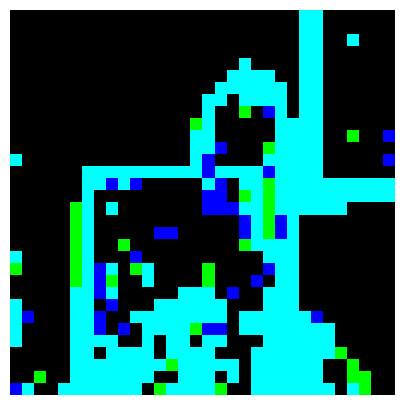

In [14]:
# Make prediction using the trained SNN model
print("Making gesture prediction...")
pred, conf, probs = predict_from_frames(frames_model)

print("\n--- Prediction Result ---")
print(f"Predicted Gesture: {gesture_labels[pred]} (Confidence: {conf:.2f})")
print(f"All probabilities: {probs}")

# Visualize model input
print("\nModel input (32x32) visualization (what the network actually sees from your video):")
display(HTML(tonic.utils.plot_animation(frames_model).to_jshtml()))

## As we can see, unfortunately the model is unable to correctly predict the gesture class due to this domain mismatch in the quality of the transformed event data for a rgb-event video sample.

* There is quite a lot of noise and missing information in between frames that isn't translated appropriately when compared to natural event data.

##  The quantized data generated in the DVSGesture evals were able to get mostly correct predictions from the model due to the quality of the input.

## This highlights a significant gap in feasibility when neuromorphic hardware is lacking and not avaiable. We hope, the results shown here spur future research in this area going forward to help bridge this gap.